In [1]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
w:\FinalYearProject\SecureSense_Project\notebooks

Files and folders here:
['01_create_fixed_splits.ipynb', '01_create_group_aware_split.ipynb', '02_logistic_regression.ipynb', '03_decision_tree.ipynb', 'SecureSense_ML.ipynb']


In [2]:
import pandas as pd

file_path = "dataset/Benign-Monday-no-metadata.parquet"

df = pd.read_parquet(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'dataset/Benign-Monday-no-metadata.parquet'

In [ ]:
print("Dataset shape:", df_all.shape)

print("\nLabel distribution:")
print(df_all["Label"].value_counts())

print("\nBinary target distribution:")
print(df_all["Target"].value_counts())

NameError: name 'df_all' is not defined

In [ ]:
print("Label values:")
print(df["Label"].value_counts())

Label values:
Label
Benign    458831
Name: count, dtype: int64


In [ ]:
import pandas as pd
import os

dataset_folder = "dataset"

files = [
    "Benign-Monday-no-metadata.parquet",
    "Botnet-Friday-no-metadata.parquet",
    "Bruteforce-Tuesday-no-metadata.parquet",
    "DDoS-Friday-no-metadata.parquet",
    "DoS-Wednesday-no-metadata.parquet",
    "Infiltration-Thursday-no-metadata.parquet",
    "Portscan-Friday-no-metadata.parquet",
    "WebAttacks-Thursday-no-metadata.parquet"
]

dataframes = []

for file in files:
    path = os.path.join(dataset_folder, file)
    print(f"Loading: {file}")
    
    temp_df = pd.read_parquet(path)
    dataframes.append(temp_df)

df_all = pd.concat(dataframes, ignore_index=True)

print("\nAll files loaded successfully!")
print("Combined shape:", df_all.shape)

Loading: Benign-Monday-no-metadata.parquet
Loading: Botnet-Friday-no-metadata.parquet
Loading: Bruteforce-Tuesday-no-metadata.parquet
Loading: DDoS-Friday-no-metadata.parquet
Loading: DoS-Wednesday-no-metadata.parquet
Loading: Infiltration-Thursday-no-metadata.parquet
Loading: Portscan-Friday-no-metadata.parquet
Loading: WebAttacks-Thursday-no-metadata.parquet

All files loaded successfully!
Combined shape: (2313810, 78)


In [ ]:
print("Number of samples in each class:")
print(df_all["Label"].value_counts())


Number of samples in each class:
Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
missing_values = df_all.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", missing_values.sum())

Columns with missing values:
Series([], dtype: int64)

Total missing values: 0


In [ ]:
import numpy as np

numeric_columns = df_all.select_dtypes(include=np.number).columns

infinite_values = np.isinf(df_all[numeric_columns]).sum()

print("Columns with infinite values:")
print(infinite_values[infinite_values > 0])

print("\nTotal infinite values:", infinite_values.sum())

Columns with infinite values:
Series([], dtype: int64)

Total infinite values: 0


In [ ]:
duplicate_count = df_all.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 82004


In [ ]:
before = len(df_all)

df_all = df_all.drop_duplicates().reset_index(drop=True)

after = len(df_all)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 2313810
Rows after removing duplicates: 2231806
Duplicates removed: 82004


In [ ]:
print(df_all.dtypes)

Protocol                       int8
Flow Duration                 int32
Total Fwd Packets             int32
Total Backward Packets        int32
Fwd Packets Length Total      int32
                             ...   
Idle Mean                   float32
Idle Std                    float32
Idle Max                      int32
Idle Min                      int32
Label                           str
Length: 78, dtype: object


In [ ]:
# Check minimum and maximum values of all numeric features

numeric_df = df_all.select_dtypes(include="number")

summary = pd.DataFrame({
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max()
})

print(summary.to_string())

                               Minimum       Maximum
Protocol                  0.000000e+00  1.700000e+01
Flow Duration            -1.300000e+01  1.200000e+08
Total Fwd Packets         1.000000e+00  2.197590e+05
Total Backward Packets    0.000000e+00  2.919220e+05
Fwd Packets Length Total  0.000000e+00  1.290000e+07
Bwd Packets Length Total  0.000000e+00  6.554530e+08
Fwd Packet Length Max     0.000000e+00  2.482000e+04
Fwd Packet Length Min     0.000000e+00  2.325000e+03
Fwd Packet Length Mean    0.000000e+00  5.940857e+03
Fwd Packet Length Std     0.000000e+00  7.125597e+03
Bwd Packet Length Max     0.000000e+00  1.953000e+04
Bwd Packet Length Min     0.000000e+00  2.896000e+03
Bwd Packet Length Mean    0.000000e+00  5.800500e+03
Bwd Packet Length Std     0.000000e+00  8.194660e+03
Flow Bytes/s             -2.610000e+08  2.071000e+09
Flow Packets/s           -2.000000e+06  4.000000e+06
Flow IAT Mean            -1.300000e+01  1.200000e+08
Flow IAT Std              0.000000e+00  8.4800

In [ ]:
negative_values = (df_all.select_dtypes(include="number") < 0).sum()

print("Columns containing negative values:")
print(negative_values[negative_values > 0])

Columns containing negative values:
Flow Duration              82
Flow Bytes/s               53
Flow Packets/s             82
Flow IAT Mean              82
Flow IAT Max               82
Flow IAT Min             2801
Fwd IAT Min                17
Fwd Header Length          35
Bwd Header Length          22
Init Fwd Win Bytes     909578
Init Bwd Win Bytes    1120793
Fwd Seg Size Min           35
dtype: int64


In [ ]:
negative_columns = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Min",
    "Fwd Header Length",
    "Bwd Header Length",
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes",
    "Fwd Seg Size Min"
]

for column in negative_columns:
    count = (df_all[column] < 0).sum()
    
    if count > 0:
        print(f"\n{column}: {count} negative values")
        print(df_all.loc[df_all[column] < 0, "Label"].value_counts())


Flow Duration: 82 negative values
Label
Benign    82
Name: count, dtype: int64

Flow Bytes/s: 53 negative values
Label
Benign    53
Name: count, dtype: int64

Flow Packets/s: 82 negative values
Label
Benign    82
Name: count, dtype: int64

Flow IAT Mean: 82 negative values
Label
Benign    82
Name: count, dtype: int64

Flow IAT Max: 82 negative values
Label
Benign    82
Name: count, dtype: int64

Flow IAT Min: 2801 negative values
Label
Benign           2608
DoS Hulk          158
DDoS               19
DoS GoldenEye       5
FTP-Patator         4
Heartbleed          4
SSH-Patator         2
Infiltration        1
Name: count, dtype: int64

Fwd IAT Min: 17 negative values
Label
DoS Hulk         8
DDoS             6
DoS GoldenEye    3
Name: count, dtype: int64

Fwd Header Length: 35 negative values
Label
Benign    35
Name: count, dtype: int64

Bwd Header Length: 22 negative values
Label
Benign    22
Name: count, dtype: int64

Init Fwd Win Bytes: 909578 negative values
Label
Benign      90957

In [ ]:
for column in negative_columns:
    negative_data = df_all.loc[df_all[column] < 0, column]

    if len(negative_data) > 0:
        print(f"\n{column}")
        print(negative_data.value_counts().head(10))


Flow Duration
Flow Duration
-1     76
-12     2
-2      2
-4      1
-13     1
Name: count, dtype: int64

Flow Bytes/s
Flow Bytes/s
-1.200000e+07    44
-6.000000e+06     2
-1.000000e+06     1
-1.930000e+08     1
-8.000000e+06     1
-6.666667e+05     1
-4.615385e+05     1
-4.000000e+06     1
-2.610000e+08     1
Name: count, dtype: int64

Flow Packets/s
Flow Packets/s
-2.000000e+06    76
-1.666667e+05     2
-1.000000e+06     2
-5.000000e+05     1
-1.538462e+05     1
Name: count, dtype: int64

Flow IAT Mean
Flow IAT Mean
-1.0     76
-12.0     2
-2.0      2
-4.0      1
-13.0     1
Name: count, dtype: int64

Flow IAT Max
Flow IAT Max
-1     76
-12     2
-2      2
-4      1
-13     1
Name: count, dtype: int64

Flow IAT Min
Flow IAT Min
-1     2664
-12      32
-2       27
-4       17
-3       17
-11      12
-13      12
-5       11
-10       4
-14       2
Name: count, dtype: int64

Fwd IAT Min
Fwd IAT Min
-1     15
-12     1
-8      1
Name: count, dtype: int64

Fwd Header Length
Fwd Header Len

In [ ]:
import numpy as np

numeric_columns = df_all.select_dtypes(include="number").columns

# Replace all negative numeric values with NaN
df_all[numeric_columns] = df_all[numeric_columns].mask(
    df_all[numeric_columns] < 0,
    np.nan
)

print("Negative values remaining:")
print((df_all[numeric_columns] < 0).sum().sum())

print("\nTotal missing values created:")
print(df_all.isnull().sum().sum())

NameError: name 'df_all' is not defined

In [ ]:
missing_values = df_all.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

Missing values by column:
Init Bwd Win Bytes    1120793
Init Fwd Win Bytes     909578
Flow IAT Min             2801
Flow Duration              82
Flow Packets/s             82
Flow IAT Mean              82
Flow IAT Max               82
Flow Bytes/s               53
Fwd Seg Size Min           35
Fwd Header Length          35
Bwd Header Length          22
Fwd IAT Min                17
dtype: int64


In [ ]:
constant_columns = [
    column for column in df_all.columns
    if df_all[column].nunique(dropna=False) <= 1
]

print("Constant columns:")
print(constant_columns)

print("\nNumber of constant columns:", len(constant_columns))

Constant columns:
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Number of constant columns: 8


In [ ]:
df_all = df_all.drop(columns=constant_columns)

print("Constant columns removed:", len(constant_columns))
print("New dataset shape:", df_all.shape)

Constant columns removed: 8
New dataset shape: (2231806, 70)


In [ ]:
df_all["Target"] = (df_all["Label"] != "Benign").astype(int)

print("Binary target distribution:")
print(df_all["Target"].value_counts())

print("\nTarget meaning:")
print("0 = Benign")
print("1 = Attack")

Binary target distribution:
Target
0    1895314
1     336492
Name: count, dtype: int64

Target meaning:
0 = Benign
1 = Attack


In [ ]:
target_percentages = df_all["Target"].value_counts(normalize=True) * 100

print("Target distribution (%):")
print(target_percentages)

print("\nBenign percentage:", round(target_percentages[0], 2), "%")
print("Attack percentage:", round(target_percentages[1], 2), "%")

Target distribution (%):
Target
0    84.922883
1    15.077117
Name: proportion, dtype: float64

Benign percentage: 84.92 %
Attack percentage: 15.08 %


In [ ]:
# Separate input features (X) and target (y)

X = df_all.drop(columns=["Label", "Target"])
y = df_all["Target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\ny distribution:")
print(y.value_counts())

NameError: name 'df_all' is not defined

In [ ]:
print("========== STEP 31: FINAL INPUT CHECK ==========")

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNumber of features:", X.shape[1])

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nData types:")
print(X.dtypes.value_counts())

print("\nMissing values in X:", X.isna().sum().sum())

========== STEP 31: FINAL INPUT CHECK ==========


NameError: name 'X' is not defined

In [ ]:
from sklearn.model_selection import train_test_split

print("========== STEP 32: TRAIN-TEST SPLIT ==========")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

========== STEP 32: TRAIN-TEST SPLIT ==========
X_train shape: (1785444, 69)
X_test shape : (446362, 69)
y_train shape: (1785444,)
y_test shape : (446362,)

Training target distribution:
Target
0    1516251
1     269193
Name: count, dtype: int64

Testing target distribution:
Target
0    379063
1     67299
Name: count, dtype: int64

Training target percentages:
Target
0    84.92
1    15.08
Name: proportion, dtype: float64

Testing target percentages:
Target
0    84.92
1    15.08
Name: proportion, dtype: float64


In [ ]:

from sklearn.model_selection import train_test_split
import pandas as pd

print("=" * 60)
print("STEP 32: DATASET INFORMATION & TRAIN-TEST SPLIT")
print("=" * 60)

# --------------------------------------------------
# 1. CHECK DATASET SIZE
# --------------------------------------------------

# Convert y to a Pandas Series if it is not already one
y = pd.Series(y).reset_index(drop=True)

# Reset X index if X is a Pandas DataFrame
if isinstance(X, pd.DataFrame):
    X = X.reset_index(drop=True)

# Check that features and target have matching rows
assert len(X) == len(y), "ERROR: X and y have different row counts!"

total_records = len(X)
total_features = X.shape[1]

print("\n--- COMPLETE DATASET ---")
print(f"Total records (rows): {total_records:,}")
print(f"Total features (columns): {total_features:,}")
print(f"Target labels: {y.nunique()}")
print(f"Total feature + target columns: {total_features + 1:,}")


# --------------------------------------------------
# 2. OVERALL CLASS DISTRIBUTION
# --------------------------------------------------

print("\n--- OVERALL CLASS DISTRIBUTION ---")

class_counts = y.value_counts()
class_percentages = (
    y.value_counts(normalize=True) * 100
).round(2)

distribution = pd.DataFrame({
    "Record Count": class_counts,
    "Percentage (%)": class_percentages
})

print(distribution.to_string())

print(f"\nTotal benign records: {class_counts.get('BENIGN', 0):,}")
print(f"Total attack records: {class_counts.get('ATTACK', 0):,}")


# --------------------------------------------------
# 3. TRAIN-TEST SPLIT (80:20)
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

train_records = len(X_train)
test_records = len(X_test)

print("\n--- TRAIN-TEST SPLIT SUMMARY ---")
print(f"Training records: {train_records:,} "
      f"({train_records / total_records * 100:.2f}%)")

print(f"Testing records: {test_records:,} "
      f"({test_records / total_records * 100:.2f}%)")

print(f"Total records after split: "
      f"{train_records + test_records:,}")


# --------------------------------------------------
# 4. SHAPES OF TRAINING AND TESTING DATA
# --------------------------------------------------

print("\n--- DATA SHAPES ---")
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)


# --------------------------------------------------
# 5. TRAINING CLASS DISTRIBUTION
# --------------------------------------------------

print("\n--- TRAINING CLASS DISTRIBUTION ---")

train_counts = y_train.value_counts()
train_percentages = (
    y_train.value_counts(normalize=True) * 100
).round(2)

train_distribution = pd.DataFrame({
    "Record Count": train_counts,
    "Percentage (%)": train_percentages
})

print(train_distribution.to_string())


# --------------------------------------------------
# 6. TESTING CLASS DISTRIBUTION
# --------------------------------------------------

print("\n--- TESTING CLASS DISTRIBUTION ---")

test_counts = y_test.value_counts()
test_percentages = (
    y_test.value_counts(normalize=True) * 100
).round(2)

test_distribution = pd.DataFrame({
    "Record Count": test_counts,
    "Percentage (%)": test_percentages
})

print(test_distribution.to_string())


# --------------------------------------------------
# 7. BENIGN AND ATTACK COUNTS
# --------------------------------------------------

print("\n--- BENIGN VS ATTACK COUNTS ---")

for label in ["BENIGN", "ATTACK"]:
    print(f"\n{label}:")
    print(f"  Overall:  {class_counts.get(label, 0):,}")
    print(f"  Training: {train_counts.get(label, 0):,}")
    print(f"  Testing:  {test_counts.get(label, 0):,}")


# --------------------------------------------------
# 8. VERIFY SPLIT
# --------------------------------------------------

print("\n--- SPLIT VERIFICATION ---")

print("All records accounted for:",
      train_records + test_records == total_records)

print("Training percentage:",
      round(train_records / total_records * 100, 2), "%")

print("Testing percentage:",
      round(test_records / total_records * 100, 2), "%")

print("\n" + "=" * 60)
print("DATASET SUMMARY COMPLETED")
print("=" * 60)

STEP 32: DATASET INFORMATION & TRAIN-TEST SPLIT


NameError: name 'y' is not defined

In [ ]:
from sklearn.impute import SimpleImputer

print("========== STEP 33: MISSING VALUE IMPUTATION ==========")

imputer = SimpleImputer(strategy="median")

# Learn median values ONLY from training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply the learned medians to test data
X_test_imputed = imputer.transform(X_test)

print("X_train before imputation:", X_train.shape)
print("X_train after imputation :", X_train_imputed.shape)

print("\nX_test before imputation:", X_test.shape)
print("X_test after imputation :", X_test_imputed.shape)

print("\nMissing values after imputation:")
print("X_train:", np.isnan(X_train_imputed).sum())
print("X_test :", np.isnan(X_test_imputed).sum())

========== STEP 33: MISSING VALUE IMPUTATION ==========
X_train before imputation: (1785444, 69)
X_train after imputation : (1785444, 69)

X_test before imputation: (446362, 69)
X_test after imputation : (446362, 69)

Missing values after imputation:
X_train: 0
X_test : 0


In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("========== STEP 34: RANDOM FOREST TRAINING ==========")

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")
rf_model.fit(X_train_imputed, y_train)

print("\nRandom Forest training completed successfully!")
print("Number of trees:", rf_model.n_estimators)
print("Number of features:", rf_model.n_features_in_)

========== STEP 34: RANDOM FOREST TRAINING ==========
Training Random Forest...

Random Forest training completed successfully!
Number of trees: 100
Number of features: 69


In [ ]:
print("========== STEP 35: MODEL PREDICTION ==========")

print("Generating predictions on test data...")

y_pred = rf_model.predict(X_test_imputed)

print("\nPredictions generated successfully!")

print("Number of predictions:", len(y_pred))

print("\nPrediction distribution:")
print(pd.Series(y_pred).value_counts())

========== STEP 35: MODEL PREDICTION ==========
Generating predictions on test data...

Predictions generated successfully!
Number of predictions: 446362

Prediction distribution:
0    378941
1     67421
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("========== STEP 36: MODEL EVALUATION ==========")

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy :  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall   :  {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-Score :  {f1:.4f} ({f1 * 100:.2f}%)")

========== STEP 36: MODEL EVALUATION ==========
Accuracy :  0.9988 (99.88%)
Precision:  0.9952 (99.52%)
Recall   :  0.9970 (99.70%)
F1-Score :  0.9961 (99.61%)


In [ ]:
from sklearn.metrics import confusion_matrix

print("========== STEP 37: CONFUSION MATRIX ==========")

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

print("\nMatrix interpretation:")
print("                 Predicted")
print("                 Benign   Attack")
print(f"Actual Benign   {cm[0,0]:8d} {cm[0,1]:8d}")
print(f"Actual Attack   {cm[1,0]:8d} {cm[1,1]:8d}")

print("\nDetailed:")
print("True Negatives (TN):", cm[0, 0])
print("False Positives (FP):", cm[0, 1])
print("False Negatives (FN):", cm[1, 0])
print("True Positives (TP):", cm[1, 1])

========== STEP 37: CONFUSION MATRIX ==========

Confusion Matrix:
[[378742    321]
 [   199  67100]]

Matrix interpretation:
                 Predicted
                 Benign   Attack
Actual Benign     378742      321
Actual Attack        199    67100

Detailed:
True Negatives (TN): 378742
False Positives (FP): 321
False Negatives (FN): 199
True Positives (TP): 67100


========== STEP 38: CONFUSION MATRIX VISUALIZATION ==========


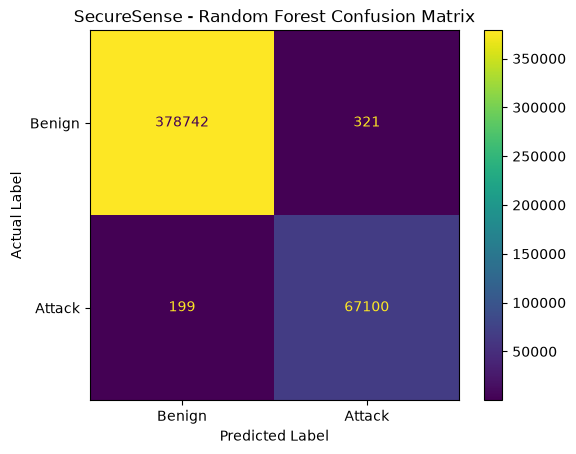

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print("========== STEP 38: CONFUSION MATRIX VISUALIZATION ==========")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
)

disp.plot(values_format="d")

plt.title("SecureSense - Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
import joblib
import os

print("========== STEP 39: SAVE ML ARTIFACTS ==========")

# Make sure the models directory exists
os.makedirs("models", exist_ok=True)

# Save the trained Random Forest model
joblib.dump(
    rf_model,
    "models/random_forest_model.pkl"
)

# Save the fitted imputer
joblib.dump(
    imputer,
    "models/feature_imputer.pkl"
)

# Save the exact feature names used by the model
joblib.dump(
    X.columns.tolist(),
    "models/feature_names.pkl"
)

print("\nML artifacts saved successfully!")

print("\nSaved files:")
print("1. models/random_forest_model.pkl")
print("2. models/feature_imputer.pkl")
print("3. models/feature_names.pkl")

========== STEP 39: SAVE ML ARTIFACTS ==========

ML artifacts saved successfully!

Saved files:
1. models/random_forest_model.pkl
2. models/feature_imputer.pkl
3. models/feature_names.pkl


In [ ]:
import joblib
import numpy as np

print("========== STEP 40: TEST SAVED MODEL ==========")

# Load saved artifacts
loaded_model = joblib.load("models/random_forest_model.pkl")
loaded_imputer = joblib.load("models/feature_imputer.pkl")
loaded_features = joblib.load("models/feature_names.pkl")

print("Saved model loaded successfully!")
print("Saved imputer loaded successfully!")
print("Saved feature list loaded successfully!")

print("\nNumber of saved features:", len(loaded_features))

# Use a small sample from the test set
sample_data = X_test.iloc[:5].copy()

# Apply the saved imputer
sample_imputed = loaded_imputer.transform(sample_data)

# Make predictions using the SAVED model
sample_predictions = loaded_model.predict(sample_imputed)

print("\nSample predictions:")
print(sample_predictions)

print("\nSample prediction labels:")

for prediction in sample_predictions:
    if prediction == 0:
        print("BENIGN")
    else:
        print("ATTACK")

========== STEP 40: TEST SAVED MODEL ==========
Saved model loaded successfully!
Saved imputer loaded successfully!
Saved feature list loaded successfully!

Number of saved features: 69

Sample predictions:
[0 0 0 0 0]

Sample prediction labels:
BENIGN
BENIGN
BENIGN
BENIGN
BENIGN


In [ ]:
import os

print("========== STEP 48B: LOCATING MODEL FILES ==========")

project_root = r"W:\FinalYearProject\SecureSense_Project"

model_files = [
    "random_forest_model.pkl",
    "feature_imputer.pkl",
    "feature_names.pkl"
]

for root, dirs, files in os.walk(project_root):
    for file in files:
        if file in model_files:
            full_path = os.path.join(root, file)
            print("FOUND:", full_path)

========== STEP 48B: LOCATING MODEL FILES ==========
FOUND: W:\FinalYearProject\SecureSense_Project\models\feature_imputer.pkl
FOUND: W:\FinalYearProject\SecureSense_Project\models\feature_names.pkl
FOUND: W:\FinalYearProject\SecureSense_Project\models\random_forest_model.pkl


In [ ]:
import os

project_root = r"W:\FinalYearProject\SecureSense_Project"

os.chdir(project_root)

print("Current working directory:")
print(os.getcwd())

Current working directory:
W:\FinalYearProject\SecureSense_Project


In [ ]:
import joblib

print("========== STEP 48D: LOAD SAVED ML ARTIFACTS ==========")

loaded_model = joblib.load("models/random_forest_model.pkl")
loaded_imputer = joblib.load("models/feature_imputer.pkl")
loaded_features = joblib.load("models/feature_names.pkl")

print("Random Forest model loaded successfully!")
print("Imputer loaded successfully!")
print("Feature names loaded successfully!")

print("\nNumber of trees:", loaded_model.n_estimators)
print("Number of features:", len(loaded_features))

========== STEP 48D: LOAD SAVED ML ARTIFACTS ==========
Random Forest model loaded successfully!
Imputer loaded successfully!
Feature names loaded successfully!

Number of trees: 100
Number of features: 69


In [ ]:
import requests
import numpy as np

print("========== STEP 48E: TEST PREDICTION API ==========")

# Create one test row using the medians learned during training
test_row = {}

for feature, median in zip(
    loaded_features,
    loaded_imputer.statistics_
):
    test_row[feature] = float(median)

# Send the test row to FastAPI
response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=test_row
)

print("HTTP Status Code:", response.status_code)

print("\nAPI Response:")
print(response.json())

========== STEP 48E: TEST PREDICTION API ==========
HTTP Status Code: 200

API Response:
{'prediction': 'BENIGN', 'prediction_code': 0, 'confidence': 100.0}


In [ ]:
import pandas as pd

print("========== STEP 51: CREATE TEST CSV ==========")

# Create one test row using the 69 features expected by the model
test_row = {}

for feature, median in zip(
    loaded_features,
    loaded_imputer.statistics_
):
    test_row[feature] = float(median)

# Create 5 identical test rows
test_csv = pd.DataFrame([test_row] * 5)

# Save the test CSV
test_csv.to_csv(
    "test_network_flows.csv",
    index=False
)

print("Test CSV created successfully!")
print("File: test_network_flows.csv")
print("Rows:", len(test_csv))
print("Columns:", len(test_csv.columns))
print("Shape:", test_csv.shape)

========== STEP 51: CREATE TEST CSV ==========
Test CSV created successfully!
File: test_network_flows.csv
Rows: 5
Columns: 69
Shape: (5, 69)


In [ ]:
def calculate_risk_test(prediction, confidence):
    """
    Test version of the SecureSense risk rules.
    """

    if prediction == 0:
        return "LOW"

    if confidence >= 0.90:
        return "CRITICAL"
    elif confidence >= 0.75:
        return "HIGH"
    elif confidence >= 0.50:
        return "MEDIUM"
    else:
        return "LOW"


print("========== STEP 54: TEST RISK LEVELS ==========")

test_cases = [
    (0, 0.99),   # Benign
    (1, 0.95),   # Attack - Critical
    (1, 0.80),   # Attack - High
    (1, 0.60),   # Attack - Medium
    (1, 0.40)    # Attack - Low
]

for prediction, confidence in test_cases:
    risk = calculate_risk_test(prediction, confidence)

    print(
        f"Prediction: {'BENIGN' if prediction == 0 else 'ATTACK':7s} | "
        f"Confidence: {confidence * 100:5.1f}% | "
        f"Risk: {risk}"
    )

========== STEP 54: TEST RISK LEVELS ==========
Prediction: BENIGN  | Confidence:  99.0% | Risk: LOW
Prediction: ATTACK  | Confidence:  95.0% | Risk: CRITICAL
Prediction: ATTACK  | Confidence:  80.0% | Risk: HIGH
Prediction: ATTACK  | Confidence:  60.0% | Risk: MEDIUM
Prediction: ATTACK  | Confidence:  40.0% | Risk: LOW


In [ ]:
import requests

print("========== STEP 56: TEST RISK API ==========")

# Create one test row from the saved training medians
test_row = {}

for feature, median in zip(
    loaded_features,
    loaded_imputer.statistics_
):
    test_row[feature] = float(median)

# Send request to FastAPI
response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=test_row
)

print("HTTP Status Code:", response.status_code)

print("\nAPI Response:")
print(response.json())

========== STEP 56: TEST RISK API ==========
HTTP Status Code: 200

API Response:
{'prediction': 'BENIGN', 'prediction_code': 0, 'confidence': 100.0, 'risk_level': 'LOW'}


In [ ]:
import pandas as pd
import os

# Make sure we are in the project directory
os.chdir(r"W:\FinalYearProject\SecureSense_Project")

# Load one of the cleaned CICIDS2017 parquet files
attack_df = pd.read_parquet(
    r"dataset\DDoS-Friday-no-metadata.parquet"
)

# Display the labels
print(attack_df["Label"].value_counts())

# Select the first attack row
attack_row = attack_df[
    attack_df["Label"] != "Benign"
].iloc[0]

print("\nSelected attack:")
print(attack_row["Label"])

Label
DDoS      128014
Benign     93250
Name: count, dtype: int64

Selected attack:
DDoS


In [ ]:
import joblib

# Load the saved model artifacts
rf_model = joblib.load(
    r"models\random_forest_model.pkl"
)

imputer = joblib.load(
    r"models\feature_imputer.pkl"
)

feature_names = joblib.load(
    r"models\feature_names.pkl"
)

# Extract only the 69 model features
attack_input = attack_row[
    feature_names
].to_frame().T

# Convert everything to numeric
for feature in feature_names:
    attack_input[feature] = pd.to_numeric(
        attack_input[feature],
        errors="coerce"
    )

# Apply the same imputer used during training
attack_input_imputed = imputer.transform(
    attack_input
)

# Predict
prediction = rf_model.predict(
    attack_input_imputed
)[0]

probabilities = rf_model.predict_proba(
    attack_input_imputed
)[0]

confidence = float(max(probabilities))

print("Prediction:", prediction)
print("Confidence:", round(confidence * 100, 2), "%")

Prediction: 1
Confidence: 100.0 %


In [ ]:
# Create a CSV containing the real attack flow we just tested

attack_test_csv = attack_row[
    feature_names
].to_frame().T

# Save it in the project root
attack_test_csv.to_csv(
    "attack_test.csv",
    index=False
)

print("Attack test CSV created successfully!")
print("Rows:", len(attack_test_csv))
print("File: attack_test.csv")

Attack test CSV created successfully!
Rows: 1
File: attack_test.csv
